In [136]:
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
import scipy.stats as stats   
import statsmodels.api as sm  
warnings.filterwarnings('ignore')

### Загрузка данных

In [137]:
# Загрузка первого файла (Москва)
df_msk = pd.read_excel(
    'Выборка компаний Москва.xlsx',
    sheet_name='report',
    header=3
)
print('Москва, shape:', df_msk.shape)
print('Колонки:', df_msk.columns[:6].tolist())

# Загрузка второго файла (регионы, кроме Москвы)
df_reg = pd.read_excel(
    'Организации кроме Москвы.xlsx',
    sheet_name='report',
    header=3
)
print('Регионы, shape:', df_reg.shape)
print('Колонки:', df_reg.columns[:6].tolist())

Москва, shape: (3647, 162)
Колонки: ['№', 'Наименование', 'Регистрационный номер', 'Дата регистрации', 'Статус', 'Код налогоплательщика']
Регионы, shape: (7525, 162)
Колонки: ['№', 'Наименование', 'Регистрационный номер', 'Дата регистрации', 'Статус', 'Код налогоплательщика']


In [138]:
# Помечаем регион и объединяем
df_msk['is_moscow'] = True
df_reg['is_moscow'] = False
df = pd.concat([df_msk, df_reg], ignore_index=True, sort=False)
print(f'Всего строк: {len(df)}')
print(f'Москва: {df["is_moscow"].sum()}')
print(f'Регионы: {(~df["is_moscow"]).sum()}')

Всего строк: 11172
Москва: 3647
Регионы: 7525


### Очистка данных

In [139]:
# Смотрим кол - во пустых строк и колонок
print('Полностью пустых строк:', df.isna().all(axis=1).sum())
print('Полностью пустых колонок:', df.isna().all(axis=0).sum())

Полностью пустых строк: 0
Полностью пустых колонок: 13


In [140]:
# Убираем пустые строки и колонки
df = df.dropna(how='all').dropna(axis=1, how='all')

In [141]:
# Переименуем ключевые колонки для удобства
rename_map = {
    '№': 'id',
    'Наименование': 'name',
    'Регистрационный номер': 'reg_num',
    'Дата регистрации': 'reg_date',
    'Статус': 'status',
    'Код налогоплательщика': 'inn',
    'Регион регистрации': 'region',
    'Код ОКАТО': 'okato',
    'Наименование ОКАТО': 'okato_name',
    'Код ОКТМО': 'oktmo',
    'Организационно-правовая форма': 'legal_form',
    'Код ОКОПФ': 'okopf'
}
df = df.rename(columns=rename_map)

In [142]:
# Смотрим только действующие фонды
df = df[df['status'] == 'Действующая'].copy()
print('Действующих:', len(df))

Действующих: 11164


In [143]:
# Функция парсинга названий колонок
def parse_col(col):
    col = str(col).replace('\xa0', ' ').strip()
    # Убираем известные суффиксы: ", RUB", ", руб.", ", чел.", ", чел"
    col = re.sub(r',\s*(RUB|руб\.?|чел\.?)\s*$', '', col, flags=re.IGNORECASE)
    m = re.match(r'^(\d{4}),\s*(.+)$', col)
    if m:
        return int(m.group(1)), m.group(2).strip()
    return None, None

# Собираем словарь: какая колонка какому году и показателю соответствует
parsed = {}
for col in df.columns:
    y, m = parse_col(col)
    if y is not None and m is not None:
        parsed[col] = (y, m)

# Годы и показатели
years = sorted(set(y for y, _ in parsed.values() if y))
metrics = sorted(set(m for _, m in parsed.values() if m))
print('Годы:', years)
print('Показателей:', len(metrics))

# Функция обратного поиска: по году и показателю вернуть название колонки
def get_col(year, metric):
    for col, (y, m) in parsed.items():
        if y == year and m == metric:
            return col
    return None

# Ключевые показатели
for year in years:
    print(year,
          '| Всего поступило:', get_col(year, 'Всего поступило средств'),
          '| Всего использовано:', get_col(year, 'Всего использовано средств'),
          '| Численность:', get_col(year, 'Среднесписочная численность работников'))

Годы: [2017, 2018, 2019, 2020, 2021]
Показателей: 28
2017 | Всего поступило: 2017, Всего поступило средств, RUB | Всего использовано: 2017, Всего использовано средств, RUB | Численность: 2017, Среднесписочная численность работников
2018 | Всего поступило: 2018, Всего поступило средств, RUB | Всего использовано: 2018, Всего использовано средств, RUB | Численность: 2018, Среднесписочная численность работников
2019 | Всего поступило: 2019, Всего поступило средств, RUB | Всего использовано: 2019, Всего использовано средств, RUB | Численность: None
2020 | Всего поступило: 2020, Всего поступило средств, RUB | Всего использовано: 2020, Всего использовано средств, RUB | Численность: None
2021 | Всего поступило: 2021, Всего поступило средств, RUB | Всего использовано: 2021, Всего использовано средств, RUB | Численность: None


In [144]:
# Конвертация чисел с учётом диапазонов
def parse_number(x): # Преобразует значение в число. Для диапазонов находит медиану.
    if pd.isna(x):
        return np.nan
    s = str(x).replace('\xa0', ' ').strip()
    if s == '' or s.lower() in ('nan', 'none', 'nat', '-'):
        return np.nan
    # Диапазон вида "0 - 5", "11 - 15", "51 - 100"
    m = re.match(r'^\s*(\d+)\s*[-–—]\s*(\d+)\s*$', s)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    # Обычное число: убираем пробелы-разделители, меняем запятую на точку
    s = s.replace(' ', '').replace(',', '.')
    try:
        return float(s)
    except ValueError:
        return np.nan

# Применяем к каждой колонке-метрике
for col in parsed:
    df[col] = df[col].apply(parse_number)

In [145]:
# Проверяем наличие дубликатов по ИНН + название + регион
dups = df[df.duplicated(subset=['inn', 'name', 'is_moscow'], keep=False)]
print(f'Найдено дублирующихся строк: {len(dups)}')
print(f'Уникальных "групп" дубликатов: {dups.groupby(["inn","name","is_moscow"]).ngroups}')

Найдено дублирующихся строк: 0
Уникальных "групп" дубликатов: 0


In [146]:
# Флаг "подал отчётность за год"
for year in years:
    col = get_col(year, 'Всего поступило средств')
    df[f'reported_{year}'] = df[col].notna() if col else False

In [147]:
# Сводка
print(f'Фондов всего: {len(df)}')
print(f'\nМосква: {df["is_moscow"].sum()}')
print(f'\nРегионы: {(~df["is_moscow"]).sum()}')
print('\nПодали отчётность по годам')
print(df[[f'reported_{y}' for y in years]].sum())
print('\nДоля подавших')
print(df[[f'reported_{y}' for y in years]].mean().round(3))

Фондов всего: 11164

Москва: 3644

Регионы: 7520

Подали отчётность по годам
reported_2017    2994
reported_2018    3396
reported_2019    3650
reported_2020    3745
reported_2021    3721
dtype: int64

Доля подавших
reported_2017    0.268
reported_2018    0.304
reported_2019    0.327
reported_2020    0.335
reported_2021    0.333
dtype: float64


### Описательный анализ (с разбивкой Москва/регионы)

In [148]:
# Распределение по ОКОПФ и региону
print(pd.crosstab(df['legal_form'], df['is_moscow']))

is_moscow                 False  True 
legal_form                            
Благотворительные фонды    6362   2973
Общественные организации      5      0
Общественные фонды         1110    616
Фонды                        15     40
Экологические фонды          28     15


In [149]:
# Доля подавших отчётность по годам: Регионы/Москва
report_share = df.groupby('is_moscow')[[f'reported_{y}' for y in years]].mean().T
report_share.index = years
report_share.columns = ['Регионы', 'Москва']
print(report_share)

       Регионы    Москва
2017  0.301064  0.200329
2018  0.332846  0.245060
2019  0.350532  0.278266
2020  0.358644  0.287596
2021  0.357314  0.283754


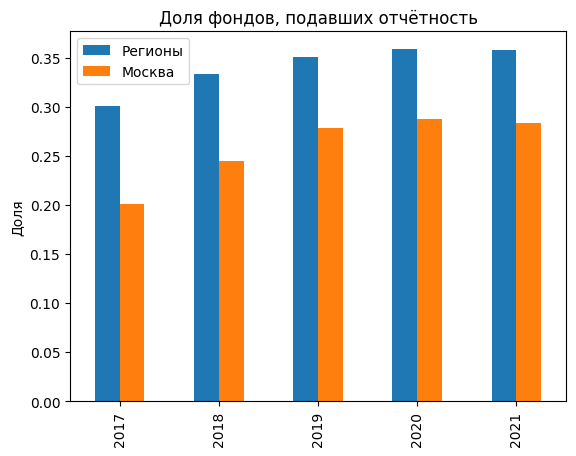

In [150]:
# Визуализация доли подавших отчётность по годам
report_share.plot(kind='bar', title='Доля фондов, подавших отчётность')
plt.ylabel('Доля')
plt.show()

In [151]:
# Медианные доходы по годам и регионам
summary = []
for year in years:
    col_inc = get_col(year, 'Всего поступило средств')
    col_staff = get_col(year, 'Среднесписочная численность работников')

    for is_msk in [True, False]:
        sub = df[(df[f'reported_{year}']) & (df['is_moscow'] == is_msk)]
        summary.append({
            'year': year,
            'is_moscow': is_msk,
            'n': len(sub),
            'median_income': sub[col_inc].median(),
            # Численность 2019-2021 = NaN по данным, поэтому median = NaN
            'median_staff': sub[col_staff].median() if col_staff else np.nan
        })

summary_df = pd.DataFrame(summary)
print(summary_df)

   year  is_moscow     n  median_income  median_staff
0  2017       True   730      3469500.0           2.5
1  2017      False  2264      1000000.0           2.5
2  2018       True   893      4154000.0          75.5
3  2018      False  2503      1194000.0          75.5
4  2019       True  1014      3695000.0           NaN
5  2019      False  2636      1131500.0           NaN
6  2020       True  1048      3817500.0           NaN
7  2020      False  2697      1188000.0           NaN
8  2021       True  1034      4920000.0           NaN
9  2021      False  2687      1305000.0           NaN


### Связь доходов и численности работников

In [152]:
# собираем таблицу: одна строка = один фонд за один год
records = []
for year in years:                                          
    cols = {                                                
        'income':   get_col(year, 'Всего поступило средств'),   
        'expenses': get_col(year, 'Всего использовано средств'),
        'staff':    get_col(year, 'Среднесписочная численность работников'),  
        'assets':   get_col(year, 'Пассивы всего'),             
        'cash':     get_col(year, 'Денежные средства и денежные эквиваленты') 
         }
    if cols['income'] is None:                              
        continue
    keep = [c for c in cols.values() if c is not None]      
    sub = df[df[f'reported_{year}']][['id','name','is_moscow'] + keep].copy()  
    sub.columns = ['id','name','is_moscow'] + [k for k,v in cols.items() if v is not None]  
    sub['year'] = year                                      
    records.append(sub)
                                         
# Объединяем все годы в один датафрейм
long_df = pd.concat(records, ignore_index=True)

# Оставляем только строки с положительным доходом
long_df = long_df[long_df['income'] > 0].copy()

In [153]:
long_df['log_income'] = np.log1p(long_df['income'])   # log(1+x), чтобы не падать на нулях
long_df['log_staff']  = np.log1p(long_df['staff'])

In [154]:
# Проходим по двум группам отдельно
for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
    sub = long_df[long_df['is_moscow'] == is_msk].dropna(subset=['log_income','log_staff'])
    if len(sub) < 3:
        print(f'{label}: мало данных (n={len(sub)})')
        continue
    # Спирмен: устойчив к выбросам и нелинейности
    rho = sub['income'].corr(sub['staff'], method='spearman')
    # Пирсон по логам — как альтернатива
    r = sub['log_income'].corr(sub['log_staff'], method='pearson')
    print(f'{label}: n={len(sub)}, Спирмен={rho:.3f}, Пирсон(лог)={r:.3f}')

Москва: n=400, Спирмен=0.497, Пирсон(лог)=0.473
Регионы: n=1383, Спирмен=0.403, Пирсон(лог)=0.401


In [155]:
# Cравнение численности по квартилям дохода в Москве(Q1 - маленькие фонды, Q4 - крупные)
sub = long_df[(long_df['is_moscow']) & long_df['staff'].notna()].copy()
if len(sub) > 0:
    # Делим доходы на 4 группы (квартили)
    sub['income_q'] = pd.qcut(sub['income'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')
    print('Москва:')
    print(sub.groupby('income_q')['staff'].describe())

Москва:
          count    mean        std  min  25%   50%   75%    max
income_q                                                       
Q1        100.0   3.140   2.294130  2.5  2.5   2.5   2.5   13.0
Q2        100.0   6.490  14.434628  2.5  2.5   2.5   2.5   75.5
Q3        100.0  11.585  26.680494  2.5  2.5   2.5   8.0  175.5
Q4        100.0  38.760  64.545751  2.5  2.5  13.0  75.5  375.5


In [156]:
# Cравнение численности по квартилям дохода по регионам
sub_reg = long_df[(~long_df['is_moscow']) & long_df['staff'].notna()].copy()
if len(sub_reg) > 0:
    sub_reg['income_q'] = pd.qcut(sub_reg['income'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')
    print('Регионы:')
    print(sub_reg.groupby('income_q')['staff'].describe().round(2))

Регионы:
          count   mean    std  min  25%  50%   75%    max
income_q                                                 
Q1        346.0   2.59   0.81  2.5  2.5  2.5   2.5   13.0
Q2        346.0   2.76   1.56  2.5  2.5  2.5   2.5   13.0
Q3        345.0   3.45   5.91  2.5  2.5  2.5   2.5   75.5
Q4        346.0  17.49  34.91  2.5  2.5  2.5  13.0  225.5


In [157]:
# Регрессия(масштабируется ли штат вместе с доходом и отличается ли наклон в Москве?)
reg_staff = long_df.dropna(subset=['log_income', 'log_staff']).copy()
reg_staff['is_moscow'] = reg_staff['is_moscow'].astype(int)
reg_staff['log_income_x_msk'] = reg_staff['log_income'] * reg_staff['is_moscow']

X = sm.add_constant(reg_staff[['log_income', 'is_moscow', 'log_income_x_msk']])
m = sm.OLS(reg_staff['log_staff'], X).fit()
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:              log_staff   R-squared:                       0.216
Model:                            OLS   Adj. R-squared:                  0.215
Method:                 Least Squares   F-statistic:                     163.6
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.16e-93
Time:                        15:13:59   Log-Likelihood:                -1912.1
No. Observations:                1783   AIC:                             3832.
Df Residuals:                    1779   BIC:                             3854.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.3360      0.127  

In [158]:
# Эластичность штата по доходу: на 1% роста дохода - сколько % роста штата
for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
    s = long_df[(long_df['is_moscow'] == is_msk)].dropna(subset=['log_income','log_staff'])
    X = sm.add_constant(s[['log_income']])
    m = sm.OLS(s['log_staff'], X).fit()
    print(f'{label}: эластичность штата по доходу = {m.params["log_income"]:.3f} (p={m.pvalues["log_income"]:.2e}, R²={m.rsquared:.3f})')

Москва: эластичность штата по доходу = 0.202 (p=1.16e-23, R²=0.223)
Регионы: эластичность штата по доходу = 0.125 (p=1.86e-54, R²=0.160)


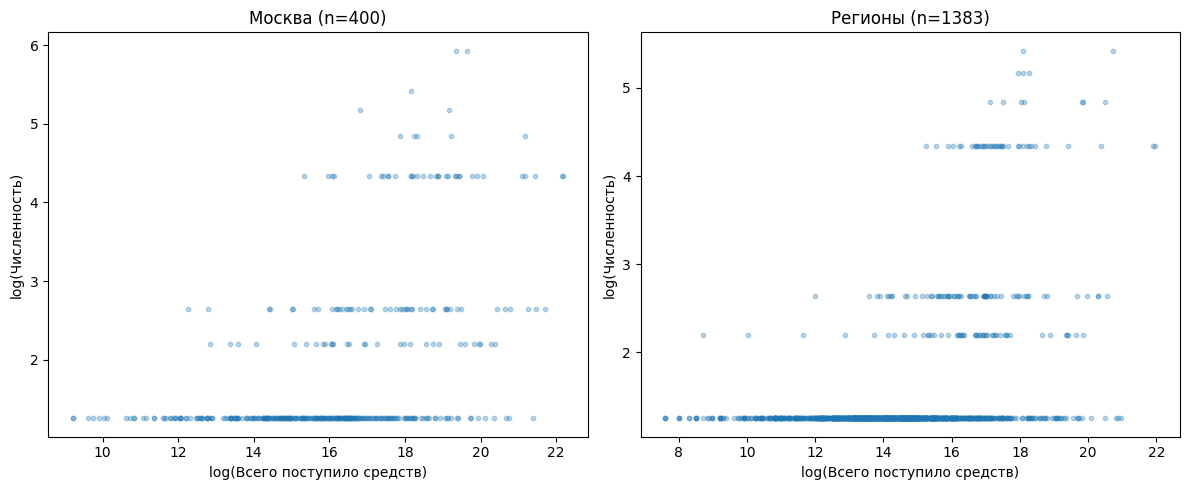

In [159]:
# Визуализация: доходы vs численность
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, is_msk, label in zip(axes, [True, False], ['Москва', 'Регионы']):
    sub = long_df[long_df['is_moscow'] == is_msk].dropna(subset=['log_income', 'log_staff'])
    ax.scatter(sub['log_income'], sub['log_staff'], alpha=0.3, s=10)
    ax.set_title(f'{label} (n={len(sub)})')
    ax.set_xlabel('log(Всего поступило средств)')
    ax.set_ylabel('log(Численность)')
plt.tight_layout()
plt.show()

### Факторы закредитованности и благополучия

In [160]:
# Собираем таблицу: одна строка = (фонд, год, показатели)
records = []
for year in years:                                          
    cols = {                                                
        'income':      get_col(year, 'Всего поступило средств'),
        'expenses':    get_col(year, 'Всего использовано средств'),
        'staff':       get_col(year, 'Среднесписочная численность работников'),
        'assets':      get_col(year, 'Пассивы всего'), # В балансе актив = пассив, поэтому используем «Пассивы всего»  вместо отсутствующего в исходных данных показателя «Активы всего
        'loans':       get_col(year, 'Заёмные средства (краткосрочные)'),
        'payables':    get_col(year, 'Кредиторская задолженность'),
        'equity':      get_col(year, 'Капитал и резервы'),
        'net_profit':  get_col(year, 'Чистая прибыль (убыток)'),
        'cash':        get_col(year, 'Денежные средства и денежные эквиваленты'),
        'receivables': get_col(year, 'Дебиторская задолженность')
    }
    if cols['income'] is None or cols['assets'] is None:    
        continue
    keep = [c for c in cols.values() if c is not None]     
    sub = df[df[f'reported_{year}']][['id','name','is_moscow','okopf'] + keep].copy()  #
    sub.columns = ['id','name','is_moscow','okopf'] + [k for k,v in cols.items() if v is not None]
    sub['year'] = year                                      
    records.append(sub)

fin = pd.concat(records, ignore_index=True) # объединяем
fin = fin.dropna(subset=['assets']) # активы обязательны
fin = fin[fin['assets'] > 0].copy() # положительные активы

In [161]:
# Считаем метрики
fin['debt_ratio'] = ((fin['loans'].fillna(0) + fin['payables'].fillna(0)) / fin['assets']).clip(0, 1) # доля долгов в активах
fin['profit_margin'] = (fin['net_profit'] / fin['income'].replace(0, np.nan)).clip(-1, 1) # чистая прибыль / доходы
fin['equity_ratio'] = (fin['equity'] / fin['assets']).clip(-1, 2) # капитал / активы

In [162]:
# Описание выборки
print(f'Всего наблюдений (фонд × год): {len(fin)}')
print(f'Москва: {fin["is_moscow"].sum()} ({fin["is_moscow"].mean()*100:.1f}%)')
print(f'Регионы: {(~fin["is_moscow"]).sum()} ({(~fin["is_moscow"]).mean()*100:.1f}%)')
# Медианы ключевых метрик по всей выборке
print(f'debt_ratio = {fin["debt_ratio"].median():.3f} ({fin["debt_ratio"].median()*100:.1f}% активов)')
print(f'profit_margin = {fin["profit_margin"].median():.3f}')
print(f'equity_ratio = {fin["equity_ratio"].median():.3f}')
print(f'income (медиана) = {fin["income"].median()/1e6:.1f} млн ₽')
print(f'assets (медиана) = {fin["assets"].median()/1e6:.1f} млн ₽')

Всего наблюдений (фонд × год): 16100
Москва: 4579 (28.4%)
Регионы: 11521 (71.6%)
debt_ratio = 0.003 (0.3% активов)
profit_margin = 0.006
equity_ratio = 0.990
income (медиана) = 1.8 млн ₽
assets (медиана) = 0.6 млн ₽


In [163]:
# Корреляции с закредитованностью
for is_msk, label in [(True,'Москва'), (False,'Регионы')]:
    sub = fin[fin['is_moscow'] == is_msk]                   
    corr = sub[['debt_ratio','income','staff','cash','receivables','equity_ratio','profit_margin']].corr(method='spearman') 
    print(f'\n{label}:')
    print(corr['debt_ratio'].sort_values(ascending=False))  


Москва:
debt_ratio       1.000000
receivables      0.091768
staff            0.083549
income           0.047267
profit_margin   -0.072430
cash            -0.075975
equity_ratio    -0.851004
Name: debt_ratio, dtype: float64

Регионы:
debt_ratio       1.000000
income           0.153440
staff            0.140488
receivables      0.085381
cash             0.017500
profit_margin   -0.059886
equity_ratio    -0.871979
Name: debt_ratio, dtype: float64


In [164]:
# Закредитованность без численности сотрудников
reg = fin.dropna(subset=['debt_ratio','income','assets','profit_margin','equity_ratio']).copy() # equity_ratio включён как контроль структуры баланса; связь - тождество, 
# поэтому интерпретируется как структурная, а не причинная
reg = reg[(reg['income'] > 0) & (reg['assets'] > 0)]
reg['log_income'] = np.log1p(reg['income'])
reg['log_assets'] = np.log1p(reg['assets'])
reg['is_moscow']  = reg['is_moscow'].astype(int)
X = sm.add_constant(reg[['log_income','log_assets','profit_margin','equity_ratio','is_moscow']])
model = sm.OLS(reg['debt_ratio'], X).fit()                       
print(model.summary())    

                            OLS Regression Results                            
Dep. Variable:             debt_ratio   R-squared:                       0.590
Model:                            OLS   Adj. R-squared:                  0.589
Method:                 Least Squares   F-statistic:                     949.4
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:13:59   Log-Likelihood:                 1113.8
No. Observations:                3304   AIC:                            -2216.
Df Residuals:                    3298   BIC:                            -2179.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.5395      0.019     28.751

In [165]:
# Регрессия закредитованности с численностью сотрудников (только 2017-2018)
reg_staff2 = reg.dropna(subset=['staff']).copy()                  
if len(reg_staff2) > 10:                                          
    reg_staff2['log_staff'] = np.log1p(reg_staff2['staff'])       
    X2 = sm.add_constant(reg_staff2[['log_income','log_staff','log_assets','is_moscow']])
    model2 = sm.OLS(reg_staff2['debt_ratio'], X2).fit()           
    print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:             debt_ratio   R-squared:                       0.129
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     16.31
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.82e-12
Time:                        15:13:59   Log-Likelihood:                 13.496
No. Observations:                 444   AIC:                            -16.99
Df Residuals:                     439   BIC:                             3.488
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5603      0.080      7.032      0.0

In [166]:
# Регрессия рентабельности
reg2 = fin.dropna(subset=['profit_margin','income','assets']).copy()  
reg2 = reg2[(reg2['income'] > 0) & (reg2['assets'] > 0)]              
reg2['log_income'] = np.log1p(reg2['income'])                          
reg2['log_assets'] = np.log1p(reg2['assets'])                          
reg2['is_moscow']  = reg2['is_moscow'].astype(int)                    
X3 = sm.add_constant(reg2[['log_income','log_assets','is_moscow']])   
model3 = sm.OLS(reg2['profit_margin'], X3).fit()                       
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:          profit_margin   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.060
Method:                 Least Squares   F-statistic:                     84.42
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           6.48e-53
Time:                        15:13:59   Log-Likelihood:                -1761.4
No. Observations:                3899   AIC:                             3531.
Df Residuals:                    3895   BIC:                             3556.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0130      0.038     -0.346      0.7

In [167]:
# Регрессия благополучия
reg3 = fin.dropna(subset=['equity_ratio','income','assets']).copy()
reg3 = reg3[(reg3['income'] > 0) & (reg3['assets'] > 0)]
reg3['log_income'] = np.log1p(reg3['income'])
reg3['log_assets'] = np.log1p(reg3['assets'])
reg3['is_moscow']  = reg3['is_moscow'].astype(int)
X4 = sm.add_constant(reg3[['log_income','log_assets','is_moscow']])
model4 = sm.OLS(reg3['equity_ratio'], X4).fit()
print(model4.summary())

                            OLS Regression Results                            
Dep. Variable:           equity_ratio   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     62.64
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           3.67e-40
Time:                        15:13:59   Log-Likelihood:                -6336.3
No. Observations:               11379   AIC:                         1.268e+04
Df Residuals:                   11375   BIC:                         1.271e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5448      0.023     23.219      0.0

In [168]:
# Сравнение закредитованности по квартилям дохода
for is_msk, label in [(True,'Москва'), (False,'Регионы')]:
    sub = fin[(fin['is_moscow'] == is_msk) & fin['debt_ratio'].notna()].copy()
    if len(sub) < 10:
        continue
    sub['income_q'] = pd.qcut(sub['income'], 4, labels=['Q1','Q2','Q3','Q4'],
                              duplicates='drop')
    desc = sub.groupby('income_q')['debt_ratio'].agg(['count','median','mean']).round(3)
    print(f'\n{label}:')
    print(desc)


Москва:
          count  median   mean
income_q                      
Q1         1145   0.002  0.220
Q2         1145   0.023  0.213
Q3         1144   0.015  0.150
Q4         1145   0.009  0.099

Регионы:
          count  median   mean
income_q                      
Q1         2881   0.000  0.190
Q2         2880   0.000  0.173
Q3         2880   0.003  0.143
Q4         2880   0.008  0.110


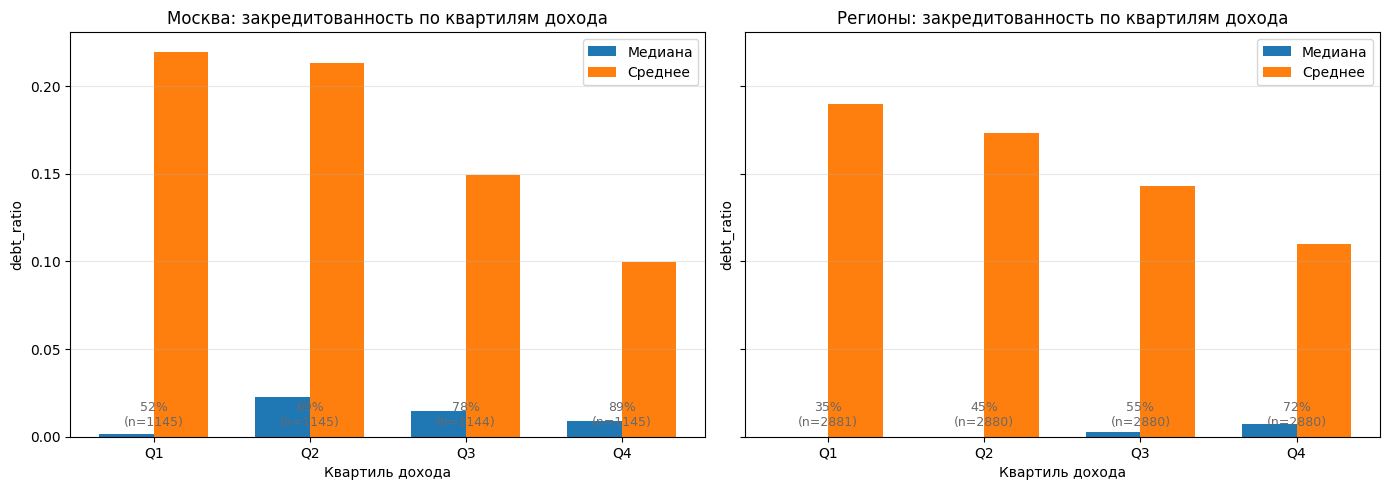

In [169]:
# График закредитованности по квартилям дохода
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, is_msk, label in zip(axes, [True, False], ['Москва', 'Регионы']):
    sub = fin[(fin['is_moscow'] == is_msk) & fin['debt_ratio'].notna()].copy()
    sub['income_q'] = pd.qcut(sub['income'], 4,
                              labels=['Q1', 'Q2', 'Q3', 'Q4'],
                              duplicates='drop')
    desc = sub.groupby('income_q')['debt_ratio'].agg(
        count='count', median='median', mean='mean',
        share_positive=lambda s: (s > 0).mean()
    )

    x = np.arange(len(desc))
    w = 0.35
    ax.bar(x - w/2, desc['median'], width=w, label='Медиана', color='tab:blue')
    ax.bar(x + w/2, desc['mean'],   width=w, label='Среднее', color='tab:orange')

    # Подписи с долей фондов, у которых долг > 0
    for xi, sp, n in zip(x, desc['share_positive'], desc['count']):
        ax.text(xi, ax.get_ylim()[1] * 0.02,
                f'{sp:.0%}\n(n={int(n)})',
                ha='center', va='bottom', fontsize=9, color='dimgray')

    ax.set_xticks(x)
    ax.set_xticklabels(desc.index.astype(str))
    ax.set_title(f'{label}: закредитованность по квартилям дохода')
    ax.set_xlabel('Квартиль дохода')
    ax.set_ylabel('debt_ratio')
    ax.grid(alpha=0.3, axis='y')
    ax.legend()

plt.tight_layout()
plt.show()

In [170]:
# Сравнение благополучия по квартилям дохода
for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
    sub = fin[(fin['is_moscow'] == is_msk)].copy()
    sub = sub[sub['income'] > 0]
    if len(sub) < 10:
        continue
    sub['income_q'] = pd.qcut(sub['income'], 4,
                              labels=['Q1', 'Q2', 'Q3', 'Q4'],
                              duplicates='drop')
    desc = sub.groupby('income_q')[['equity_ratio', 'profit_margin']].median().round(3)
    print(f'\n{label}:')
    print(desc)


Москва:
          equity_ratio  profit_margin
income_q                             
Q1               0.989          0.111
Q2               0.964          0.009
Q3               0.959          0.009
Q4               0.976          0.009

Регионы:
          equity_ratio  profit_margin
income_q                             
Q1               1.000         -0.006
Q2               1.000          0.003
Q3               0.993          0.007
Q4               0.980          0.004


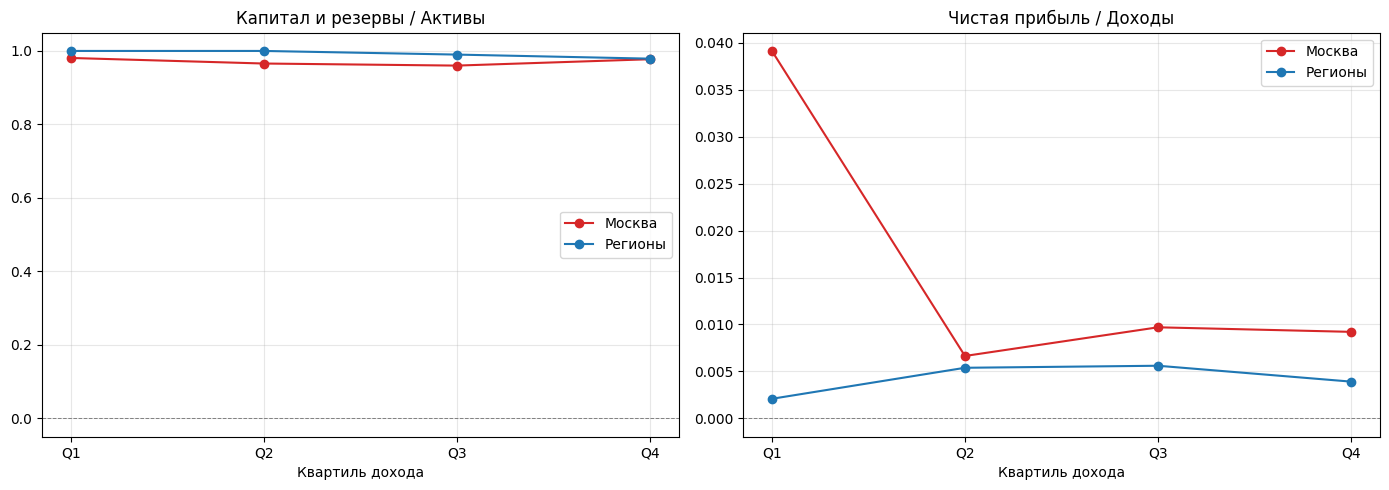

In [171]:
# График благополучия по квартилям
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in zip(axes,
                          ['equity_ratio', 'profit_margin'],
                          ['Капитал и резервы / Активы',
                           'Чистая прибыль / Доходы']):
    for is_msk, label, color in [(True, 'Москва', 'tab:red'),
                                 (False, 'Регионы', 'tab:blue')]:
        sub = fin[(fin['is_moscow'] == is_msk) & (fin['income'] > 0)]
        sub = sub.dropna(subset=[col])
        sub['income_q'] = pd.qcut(sub['income'], 4,
                                  labels=['Q1', 'Q2', 'Q3', 'Q4'],
                                  duplicates='drop')
        med = sub.groupby('income_q')[col].median()
        ax.plot(med.index.astype(str), med.values,
                marker='o', label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel('Квартиль дохода')
    ax.axhline(0, color='gray', linewidth=0.7, linestyle='--')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Сравнение Москва vs регионы

In [172]:
# Медианы ключевых метрик
compare_metrics = ['income', 'expenses', 'assets', 'staff',
                   'debt_ratio', 'profit_margin', 'equity_ratio']

# Оставляем только те метрики, которые реально есть в fin
compare_metrics = [m for m in compare_metrics if m in fin.columns]

summary_rows = []
for year in years:
    sub = fin[fin['year'] == year]
    for is_msk in [True, False]:
        s = sub[sub['is_moscow'] == is_msk]
        row = {'year': year, 'is_moscow': is_msk, 'n': len(s)}
        for m in compare_metrics:
            row[m] = s[m].median() if m in s else np.nan
        summary_rows.append(row)

cmp_df = pd.DataFrame(summary_rows)
print('Медианы ключевых метрик по годам:')
print(cmp_df.to_string(index=False))

Медианы ключевых метрик по годам:
 year  is_moscow    n    income  expenses    assets  staff  debt_ratio  profit_margin  equity_ratio
 2017       True  700 4218000.0 4319500.0 2214000.0    2.5    0.013216       0.013843      0.967896
 2017      False 2027 1221000.0 1208500.0  292000.0    2.5    0.000273       0.008026      0.998828
 2018       True  857 4471000.0 4413000.0 1913000.0   75.5    0.013788       0.011892      0.970000
 2018      False 2255 1435000.0 1390000.0  354000.0   75.5    0.000386       0.005510      0.998158
 2019       True  989 4000000.0 3891500.0 1844000.0    NaN    0.015234       0.010473      0.963369
 2019      False 2359 1358000.0 1338500.0  374000.0    NaN    0.000461       0.004149      0.995524
 2020       True 1024 4100500.0 3634000.0 2488500.0    NaN    0.008920       0.007176      0.976000
 2020      False 2430 1426000.0 1301000.0  413500.0    NaN    0.000563       0.002084      0.995430
 2021       True 1009 5168000.0 4729000.0 2770000.0    NaN    0.00

In [173]:
# Средние значения ключевых метрик
cmp_mean = (fin
            .groupby(['year', 'is_moscow'])[compare_metrics]
            .mean()
            .round(2))
print('Средние значения:')
print(cmp_mean)

Средние значения:
                      income      expenses        assets  staff  debt_ratio   
year is_moscow                                                                
2017 False      1.702091e+07  1.631622e+07  2.386516e+07   4.85        0.16  \
     True       6.320333e+07  6.493832e+07  6.028644e+07  10.05        0.18   
2018 False      1.863522e+07  1.962211e+07  2.169007e+07  96.93        0.16   
     True       1.475938e+08  2.066841e+08  5.771837e+07  97.24        0.17   
2019 False      2.276054e+07  2.126740e+07  2.424309e+07    NaN        0.16   
     True       9.754789e+07  7.547820e+07  1.651307e+09    NaN        0.18   
2020 False      2.616303e+07  2.318731e+07  2.084887e+07    NaN        0.15   
     True       7.853735e+07  7.496236e+07  7.055615e+07    NaN        0.16   
2021 False      1.229823e+08  1.148472e+08  5.151312e+07    NaN        0.15   
     True       8.644465e+07  7.112997e+07  7.308473e+07    NaN        0.16   

                profit_margin  eq

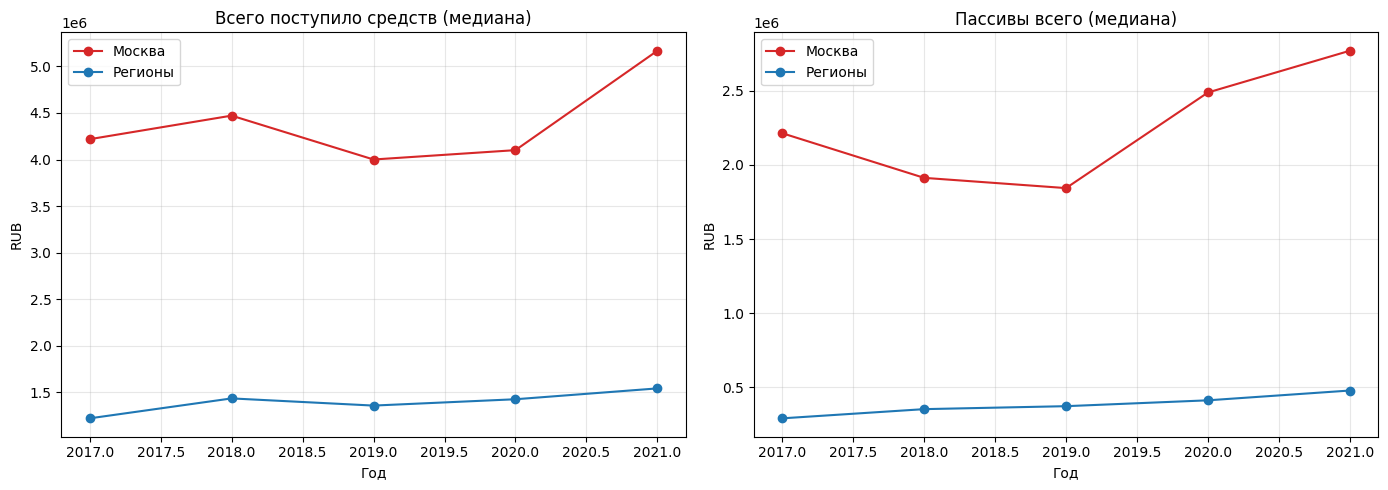

In [174]:
# Графики доходов и активов
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes,
                             ['income', 'assets'],
                             ['Всего поступило средств (медиана)',
                              'Пассивы всего (медиана)']):
    for is_msk, label, color in [(True, 'Москва', 'tab:red'),
                                 (False, 'Регионы', 'tab:blue')]:
        sub = cmp_df[cmp_df['is_moscow'] == is_msk]
        ax.plot(sub['year'], sub[metric], marker='o', label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel('Год')
    ax.set_ylabel('RUB')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [175]:
# Структура расходов
# Создаем отдельный датафрейм structure: одна строка = (фонд, год)
records = []
for year in years:
    cols = {
        'expenses':  get_col(year, 'Всего использовано средств'),
        'target':    get_col(year, 'Расходы на целевые мероприятия'),
        'admin':     get_col(year, 'Расходы на содержание аппарата управления'),
        'equipment': get_col(year, 'Приобретение основных средств, инвентаря и иного имущества'),
    }
    if cols['expenses'] is None:
        continue
    keep = [c for c in cols.values() if c is not None]
    sub = df[df[f'reported_{year}']][['id', 'is_moscow'] + keep].copy()
    sub.columns = ['id', 'is_moscow'] + [k for k, v in cols.items() if v is not None]
    sub['year'] = year
    records.append(sub)

structure = pd.concat(records, ignore_index=True)
structure = structure[structure['expenses'] > 0].copy()

# Доли расходов
for src, dst in [('target',    'share_target'),
                 ('admin',     'share_admin'),
                 ('equipment', 'share_equipment')]:
    if src in structure.columns:
        structure[dst] = (structure[src] / structure['expenses']).clip(0, 1)

print(structure[['share_target', 'share_admin', 'share_equipment']]
      .describe().round(3))

       share_target  share_admin  share_equipment
count     14132.000    12755.000         2730.000
mean          0.800        0.298            0.154
std           0.241        0.323            0.258
min           0.000        0.000            0.000
25%           0.731        0.063            0.005
50%           0.886        0.162            0.029
75%           0.981        0.415            0.166
max           1.000        1.000            1.000


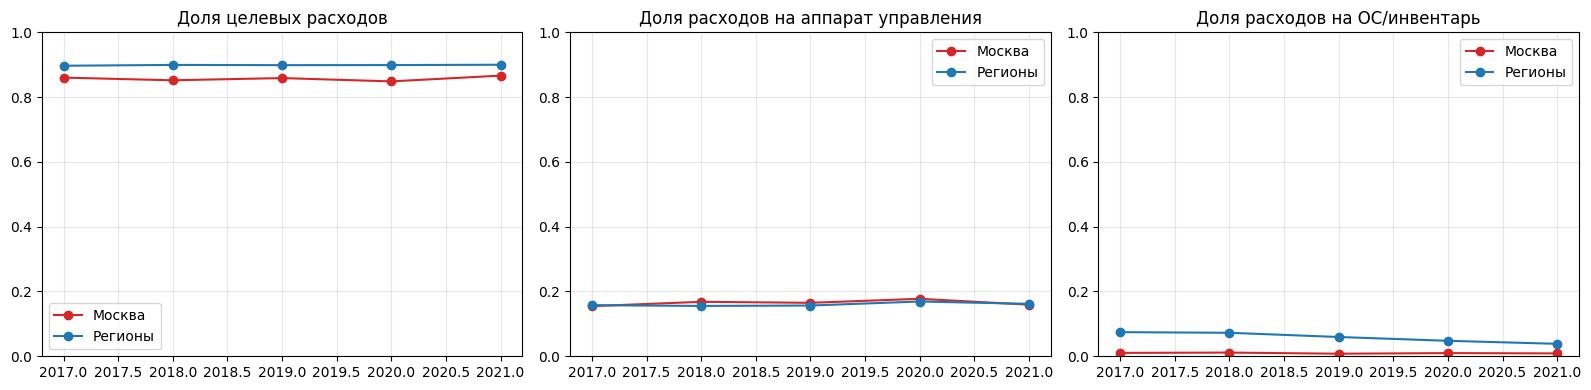

In [176]:
# Графики структуры расходов
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
        axes,
        ['share_target', 'share_admin', 'share_equipment'],
        ['Доля целевых расходов',
         'Доля расходов на аппарат управления',
         'Доля расходов на ОС/инвентарь']):
    for is_msk, label, color in [(True, 'Москва', 'tab:red'),
                                 (False, 'Регионы', 'tab:blue')]:
        sub = structure[structure['is_moscow'] == is_msk]
        med = sub.groupby('year')[col].median()
        ax.plot(med.index, med.values, marker='o', label=label, color=color)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [177]:
# Тест Манна - Уитни для проверки отличий Москвы и регионов по каждой метрике.
from scipy.stats import mannwhitneyu

test_rows = []
for metric in ['income', 'assets', 'debt_ratio', 'profit_margin',
               'equity_ratio', 'staff']:
    if metric not in fin.columns:
        continue
    msk = fin.loc[fin['is_moscow'], metric].dropna()
    reg = fin.loc[~fin['is_moscow'], metric].dropna()
    if len(msk) < 30 or len(reg) < 30:
        continue
    stat, p = mannwhitneyu(msk, reg, alternative='two-sided')
    test_rows.append({
        'metric':      metric,
        'n_msk':       len(msk),
        'n_reg':       len(reg),
        'median_msk':  msk.median(),
        'median_reg':  reg.median(),
        'U_stat':      stat,
        'p_value':     p,
        'significant': p < 0.05,
    })

mw_df = pd.DataFrame(test_rows).sort_values('p_value')
print('Тест Манна–Уитни: Москва vs Регионы')
print(mw_df.to_string(index=False))

Тест Манна–Уитни: Москва vs Регионы
       metric  n_msk  n_reg   median_msk   median_reg     U_stat       p_value  significant
       assets   4579  11521 2.259000e+06 3.820000e+05 34585326.0 5.380469e-209         True
       income   4579  11521 4.450000e+06 1.393000e+06 32786755.0 3.113785e-128         True
 equity_ratio   3438   7950 9.708481e-01 9.967422e-01 10909256.5  4.523703e-69         True
   debt_ratio   4579  11521 1.145038e-02 5.212406e-04 30628202.5  3.744863e-62         True
        staff    397   1298 2.500000e+00 2.500000e+00   304156.5  5.787801e-17         True
profit_margin   1571   2334 9.727626e-03 4.439657e-03  2031495.0  9.694514e-09         True


### Дополнительные проверки

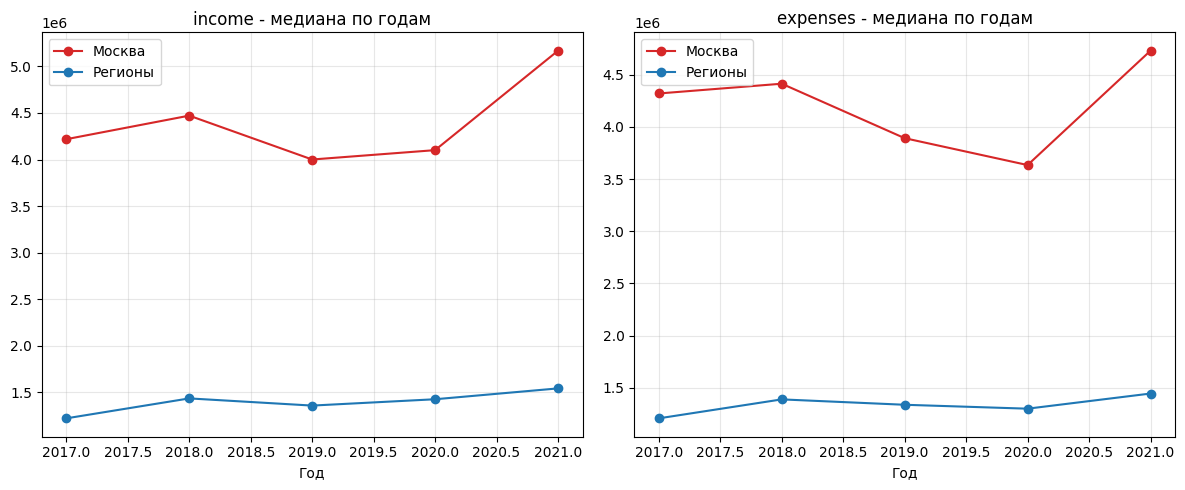

In [178]:
# Как менялись ключевые метрики во времени: Москва vs Регионы
year_metrics = ['income', 'expense_ratio' if 'expense_ratio' in fin.columns else 'expenses',
                'equity_ratio', 'debt_ratio']
year_metrics = [m for m in year_metrics if m in fin.columns]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes = axes.ravel()

for ax, m in zip(axes, year_metrics):
    for is_msk, label, color in [(True, 'Москва', 'tab:red'),
                                 (False, 'Регионы', 'tab:blue')]:
        sub = fin[fin['is_moscow'] == is_msk]
        med = sub.groupby('year')[m].median()
        ax.plot(med.index, med.values, marker='o', label=label, color=color)
    ax.set_title(f'{m} - медиана по годам')
    ax.set_xlabel('Год')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [179]:
# Связь численности сотрудников и благополучия компании
# Численность есть только за 2017–2018, поэтому используем только эти годы
for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
    sub = (fin[fin['is_moscow'] == is_msk]
           .dropna(subset=['staff', 'equity_ratio', 'profit_margin']))
    sub = sub[sub['staff'] > 0]
    if len(sub) < 3:
        print(f'{label}: мало данных (n={len(sub)})')
        continue

    # Спирмен: устойчив к выбросам и нелинейности
    rho_eq, p_eq = stats.spearmanr(sub['staff'], sub['equity_ratio'])
    rho_pm, p_pm = stats.spearmanr(sub['staff'], sub['profit_margin'])

    print(f'{label}: n={len(sub)}, '
          f'staff-equity ρ={rho_eq:.3f} (p={p_eq:.2e}), '
          f'staff-profit ρ={rho_pm:.3f} (p={p_pm:.2e})')

Москва: n=172, staff-equity ρ=0.061 (p=4.25e-01), staff-profit ρ=-0.058 (p=4.54e-01)
Регионы: n=274, staff-equity ρ=-0.190 (p=1.59e-03), staff-profit ρ=-0.039 (p=5.16e-01)


In [180]:
# Связь благополучия и закредитованности
fin['has_debt'] = (fin['debt_ratio'] > 0).astype(int)

print('Сравнение фондов с долгом и без (медианы):')
grp = (fin
       .groupby(['is_moscow', 'has_debt'])[['income', 'profit_margin',
                                            'equity_ratio', 'assets']]
       .median()
       .round(3))
print(grp)

# Доля фондов с ненулевым долгом по квартилям дохода
for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
    sub = fin[(fin['is_moscow'] == is_msk) & (fin['income'] > 0)].copy()
    if len(sub) < 30:
        continue
    sub['income_q'] = pd.qcut(sub['income'], 4,
                              labels=['Q1', 'Q2', 'Q3', 'Q4'],
                              duplicates='drop')
    share = sub.groupby('income_q')['has_debt'].mean().round(3)
    print(f'\n{label} - доля фондов с долгом > 0 по квартилям дохода:')
    print(share)

Сравнение фондов с долгом и без (медианы):
                       income  profit_margin  equity_ratio     assets
is_moscow has_debt                                                   
False     0          778000.0          0.003         1.000   158000.0
          1         2505000.0          0.005         0.915   967500.0
True      0         1087000.0          0.001         1.000   260000.0
          1         7590000.0          0.011         0.933  4483000.0

Москва - доля фондов с долгом > 0 по квартилям дохода:
income_q
Q1    0.518
Q2    0.689
Q3    0.785
Q4    0.888
Name: has_debt, dtype: float64

Регионы - доля фондов с долгом > 0 по квартилям дохода:
income_q
Q1    0.348
Q2    0.447
Q3    0.552
Q4    0.717
Name: has_debt, dtype: float64


In [181]:
# Топ-фонды по медианному доходу(берем > 3, чтобы отсеять случайные одно-двухлетние наблюдения и оставить только крупные и стабильные фонды)
fund_stats = (fin[fin['income'] > 0]
              .groupby('id')
              .agg(n_years=('year', 'nunique'),
                   median_income=('income', 'median'),
                   median_staff=('staff', 'median'),
                   median_equity_ratio=('equity_ratio', 'median'),
                   is_moscow=('is_moscow', 'first')))

top_income = (fund_stats[fund_stats['n_years'] >= 3]
              .sort_values('median_income', ascending=False)
              .head(10))

# Подтягиваем названия
name_map = df.set_index('id')['name'].to_dict()
top_income['name'] = top_income.index.map(name_map)

print('Топ-10 фондов по медианному доходу (≥3 лет отчётности):')
print(top_income[['name', 'is_moscow', 'n_years',
                  'median_income', 'median_staff',
                  'median_equity_ratio']].round(0))

Топ-10 фондов по медианному доходу (≥3 лет отчётности):
                                                   name  is_moscow  n_years   
id                                                                            
3347                                   ЛЮБОВЬ ДЕТЯМ, БФ       True        4  \
6919                     ФОНД КАПИТАЛЬНОГО РЕМОНТА, НКО      False        5   
1011  БФ ПОДДЕРЖКИ РАБОТНИКОВ СКОРОЙ МЕДИЦИНСКОЙ ПОМОЩИ       True        5   
3650                МИРНЫЙ АТОМ, БЛАГОТВОРИТЕЛЬНЫЙ ФОНД      False        3   
2645                         ЗДОРОВЫЙ ОБРАЗ ЖИЗНИ, КРОФ       True        5   
2317                              ДОСТОЙНЫМ-ЛУЧШЕЕ, НБФ       True        5   
7235                                       ЦСП, БО ФОНД      False        5   
2804                          ИМЕНИ ДЖ.КОРКМАСОВА, РОБФ       True        5   
6601                                       ТАТНЕФТЬ, БФ      False        5   
2186                          ДОБРЫЕ СЕРДЦА БАЙКАЛА, БФ       True        5

In [182]:
# Сколько лет фонд сдавал отчётность
regularity = pd.DataFrame({
    'n_years': df[[f'reported_{y}' for y in years]].sum(axis=1),
    'is_moscow': df['is_moscow'],
})

reg_tab = (regularity
           .groupby(['n_years', 'is_moscow'])
           .size()
           .unstack(fill_value=0))
reg_tab.columns = ['Регионы', 'Москва']

print('Сколько лет фонд подавал отчётность (2017–2021):')
print(reg_tab)

# Доля фондов, подавших отчётность ≥3 лет
share_3plus = (regularity
               .groupby('is_moscow')['n_years']
               .apply(lambda s: (s >= 3).mean()))
print('\nДоля фондов с ≥3 годами отчётности:')
print(f"Регионы: {share_3plus.get(False, np.nan):.1%}")
print(f"Москва:  {share_3plus.get(True,  np.nan):.1%}")

Сколько лет фонд подавал отчётность (2017–2021):
         Регионы  Москва
n_years                 
0           3791    2236
1            639     238
2            557     218
3            529     228
4            573     259
5           1431     465

Доля фондов с ≥3 годами отчётности:
Регионы: 33.7%
Москва:  26.1%


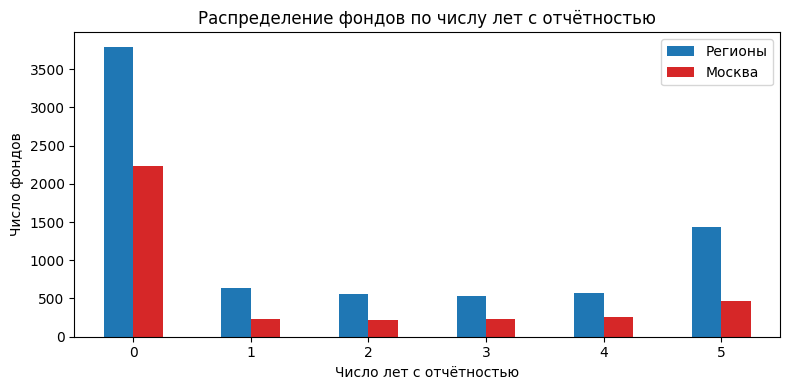

In [183]:
# Визуализация
fig, ax = plt.subplots(figsize=(8, 4))
reg_tab.plot(kind='bar', ax=ax, color=['tab:blue', 'tab:red'])
ax.set_title('Распределение фондов по числу лет с отчётностью')
ax.set_xlabel('Число лет с отчётностью')
ax.set_ylabel('Число фондов')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [184]:
# Доля расходов на аппарат управления по размеру фонда
if 'structure' in dir() and len(structure) > 0:
    sub = structure.dropna(subset=['share_admin', 'expenses']).copy()
    sub = sub[sub['expenses'] > 0]
    sub['size_q'] = pd.qcut(sub['expenses'], 4,
                            labels=['Q1', 'Q2', 'Q3', 'Q4'],
                            duplicates='drop')
    for is_msk, label in [(True, 'Москва'), (False, 'Регионы')]:
        s = sub[sub['is_moscow'] == is_msk]
        if len(s) < 30:
            continue
        tab = s.groupby('size_q')['share_admin'].median().round(3)
        print(f'\n{label} - медиана доли расходов на аппарат управления по квартилям расходов:')
        print(tab)


Москва - медиана доли расходов на аппарат управления по квартилям расходов:
size_q
Q1    0.911
Q2    0.251
Q3    0.170
Q4    0.109
Name: share_admin, dtype: float64

Регионы - медиана доли расходов на аппарат управления по квартилям расходов:
size_q
Q1    0.354
Q2    0.188
Q3    0.139
Q4    0.069
Name: share_admin, dtype: float64


### Итоговые выводы

### 1. Очистка и описание данных
Загружены два файла, объединены в один датафрейм. Удалены 13 полностью пустых колонок, полностью пустых строк не было. Переименованы ключевые поля. Числа сконвертированы в float с обработкой пробелов, запятых и диапазонов вида «0 - 5» (заменяются медианой диапазона). Дубликатов по ИНН + названию + региону - 0. Создан флаг reported_{year} - сдал ли фонд отчётность за год. Данные приведены к формату «фонд × год» (16 100 наблюдений) и к длинному формату (long_df).

Всего действующих фондов - 11 164: Москва - 3 644 , регионы - 7 520. Наблюдений «фонд × год» - 16 100: Москва - 4 579, регионы - 11 521.

Доля фондов, подавших отчётность, растёт с 26.8% в 2017 до 33.3% в 2021. Регионы сдают чаще Москвы во все годы: в последний отчетный год(2021) - 35.7% против 28.4%. Регулярно (≥3 лет из 5) сдают только 33.7% региональных и 26.1% московских фондов.

Структура по ОКОПФ: Благотворительные фонды доминируют - их подавляющее большинство(примерно 83.6%). Общественные фонды составляют примерно 15.5%. Экологические фонды - 43 единицы, Общественные организации 5 единиц и остальные «Фонды» 55 единиц. 

Главное ограничение данных: Численность работников доступна только за 2017 - 2018, поэтому все выводы о штате ограничены этими двумя годами.

### 2. Связь между материальным благополучием фонда и количеством штатных работников
Связь есть, но она умеренная и нелинейная.

Доход и численность (для сдавших отчётность). В Москве n=400, Спирмен 0.497, Пирсон по логам 0.473. В регионах n=1383, Спирмен 0.403, Пирсон по логам 0.401. Оба коэффициента положительные и значимые (p<0.001). Связь сильнее в Москве. Интерпретация: Коэффициенты Спирмена и Пирсона близки друг к другу - значит, связь устойчивая и не «ломается» от выбросов или нелинейности. Значение около 0.5 в Москве означает умеренную положительную связь: в целом фонды с большим доходом держат больше сотрудников, но разброс большой - есть и крупные по доходу фонды с маленьким штатом, и наоборот. В регионах связь заметно слабее (около 0.4) - там доход и штат «расходятся» сильнее, вероятно, из-за большего числа фондов, работающих на волонтёрах и подрядчиках, а не на штатных сотрудниках. Разница между Москвой и регионами содержательная: в столице рост доходов чаще сопровождается наймом, в регионах чаще ростом программных расходов без расширения штата.

Эластичность штата по доходу (насколько % растёт штат при +1% дохода). В Москве 0.202 (p=1.2e-23, R²=0.223). В регионах 0.125 (p=1.9e-54, R²=0.160). Интерпретация: +1% дохода даёт +0.13 - 0.20% роста штата. Фонды масштабируют штат слабее, чем растут доходы, - вероятно, растут программные расходы, подрядчики и волонтёры. Регрессия с взаимодействием log_income × is_moscow подтвердила: в Москве эластичность значимо выше (коэф. взаимодействия +0.077, p<0.001).

Численность по квартилям дохода в Москве. Q1 (мелкие): медиана штата 2.5, среднее 3.1. Q2: медиана 2.5, среднее 6.5. Q3: медиана 2.5, среднее 11.6. Q4 (крупные): медиана 13.0, среднее 38.8. Штат растёт только в верхних квартилях - до Q3 медиана держится на 2.5 (минимальный штат). В регионах аналогично, но рост слабее: в Q4 медиана 2.5, среднее 17.5.

Численность и финансовое благополучие (equity_ratio, profit_margin). В Москве n=172: staff~equity ρ=0.061 (p=0.43), staff~profit ρ=−0.058 (p=0.45) - связи нет. В регионах n=274: staff~equity ρ=−0.190 (p=0.002) - слабая, отрицательно значимая, staff~profit ρ=−0.039 (p=0.52) - незначимая. В Москве крупный штат не означает финансового благополучия. В регионах чем больше штат, тем ниже доля собственного капитала (вероятно, из-за роста обязательств - зарплат, аренды).

Итоговый выыод по пункту 2. Связь между материальным благополучием и численностью есть, но она умеренная и нелинейная. Доход и штат связаны положительно (ρ=0.40 - 0.50), но эластичность низкая (0.13 - 0.20) - фонды растут в деньгах быстрее, чем в штате. С финансовой устойчивостью (equity_ratio) численность не связана в Москве и слабо отрицательно связана в регионах.

### 3. Факторы, влияющие на закредитованность и финансовое благополучие

### 3.1. Факторы закредитованности (доля долгов в активах)

Медиана доли долгов в активах 0.003 - фонды почти не берут займы.

Корреляции (Спирмен). С долей собственного капитала: Москва −0.851, регионы −0.872. С доходом: Москва +0.047, регионы +0.153. С численностью: Москва +0.084, регионы +0.140. С дебиторской задолженностью: Москва +0.092, регионы +0.085. С денежными средствами: Москва −0.076, регионы +0.018. С рентабельностью: Москва −0.072, регионы −0.060.

Регрессия без численности сотрудников (n=3304, R²=0.59). Доля собственного капитала −0.434 (p<0.001) - структурно. Логарифм активов −0.007 (p<0.001) - слабо значим. Москва +0.014 (p=0.030) - значим. Логарифм дохода +0.002 (p=0.28) - не значим. Рентабельность +0.007 (p=0.41) - не значим.

Регрессия с численностью (n=444, 2017–2018). Логарифм активов −0.042 (p<0.001) - значим. Москва +0.071 (p=0.004) - значим. Логарифм дохода +0.013 (p=0.081) - на грани(формально не значим, но эффект похож на реальный - не хватает выборки, чтобы это уверенно подтвердить). Логарифм численности +0.007 (p=0.574) - не значим.

Доля фондов с ненулевым долгом растёт с доходом: в Москве с 52% в Q1 до 89% в Q4, в регионах с 35% до 72%. Крупные фонды чаще имеют долг, но его уровень остаётся низким.

Главный фактор - структурный (equity_ratio, ρ≈−0.86): это балансовое тождество, а не «эффект».

Закредитованность фонда зависит от двух вещей: 
1) Размер активов. Чем крупнее фонд по активам, тем ниже его закредитованность. Коэффициент −0.007 (p<0.001): крупные фонды реже берут долги относительно своего размера. Логика: у крупного фонда больше собственных ресурсов, и ему не нужно занимать, чтобы закрыть текущие расходы.
2) Регион. Московские фонды более закредитованы, чем региональные: коэффициент +0.014 (p=0.03), то есть закредитованность выше на 1.4 процентных пункта. Логика: в Москве дороже аренда, зарплаты, административные расходы - фонды чаще привлекают заёмные средства, чтобы покрыть эти расходы.

### 3.2. Факторы финансового благополучия (доля собственного капитала в активах)

Медиана 0.99 - фонды почти полностью на собственных средствах.

Регрессия (n=11379, R²=0.016). Логарифм дохода +0.0055 (p=0.016) - слабо значим. Логарифм активов +0.0138 (p<0.001) - значим. Москва −0.075 (p<0.001) - значим.

Рентабельность (чистая прибыль / доход). Регрессия (n=3899, R²=0.061): логарифм дохода −0.039 (p<0.001), логарифм активов +0.044 (p<0.001), Москва +0.054 (p<0.001). Крупные по доходу фонды менее рентабельны, крупные по активам - более рентабельны. Москва значимо повышает рентабельность: медиана 0.97% против 0.44% в регионах.

Финансовая устойчивость (доля собственного капитала) слабо положительно связана с размером. У крупных фондов чуть выше, а у московских - заметно ниже (на −0.075(7.5 п.п.), то есть у них больше долгов). Рентабельность выше в Москве и у фондов с большими активами, но ниже у фондов с большим доходом - крупные фонды работают с большим оборотом, но меньшей прибылью.

### 4. Дополнительные проверки

Москва vs регионы (Mann - Whitney U). Доход: 4.45 против 1.39 млн ₽ (p=3e-128). Активы: 2.26 против 0.38 млн ₽ (p=5e-209). Доля долгов в активах: 0.011 против 0.0005 (p=4e-62). Доля собственного капитала: 0.971 против 0.997 (p=5e-69). Рентабельность: 0.0097 против 0.0044 (p=1e-8). Все различия значимы. Московские фонды в 3 - 4 раза крупнее по доходу и в 6 раз по активам, чуть более закредитованы, но более рентабельны.

Эффект масштаба в структуре расходов. Медиана доли расходов на аппарат управления по квартилям расходов. Москва: Q1 91.1%, Q2 25.1%, Q3 17.0%, Q4 10.9%. Регионы: Q1 35.4%, Q2 18.8%, Q3 13.9%, Q4 6.9%. Гипотеза «у крупных фондов дорогой аппарат» опровергнута: чем крупнее фонд, тем меньше доля аппарата. Крупные фонды держат 7–11% = из каждого рубля расходов на управление уходит 7–11 копеек, это здоровая норма для НКО. Мелкие фонды тратят до 91% = из каждого рубля 91 копейка уходит на управление, но не потому, что у них раздутый аппарат, а потому, что сам бюджет маленький, и фиксированные расходы (зарплата директора, бухгалтер, аренда) составляют в нём большую долю. Московские фонды «дороже» по аппарату: разрыв 3 - 5 п.п. в Q2 - Q4 и 56 п.п. в Q1.

Регулярность отчётности. Регионы: 0 лет - 3791, 1 - 2 года - 1196, ≥3 лет - 2533. Москва: 0 лет - 2236, 1 - 2 года - 456, ≥3 лет - 952. Только около 1/3 фондов сдаёт отчётность регулярно. Остальные - нерегулярные, их данные не образуют устойчивой панели. Все сравнения по благополучию и численности валидны для около 3500 фондов, а не для всех 11 164.

Топ-10 по медианному доходу (≥3 лет отчётности). Медианный доход 1.7 - 4.8 млрд ₽. У всех доля собственного капитала ≈ 1.0 -  не используют заёмное финансирование. Численность 2 - 176 человек -  разброс штата большой, что иллюстрирует нелинейность, но не отменяет общую положительную связь.

Устойчивость во времени. Медианный доход московских фондов: 3.5 млн ₽ (2017) - 5.2 млн ₽ (2021); региональных: 1.0 - 1.5 млн ₽. Доля собственного капитала стабильна: 0.96-0.98 в Москве, 0.995-0.999 в регионах. 

### Российские фонды - сектор организаций с низкой закредитованностью и высокой долей собственного капитала. Численность растёт с доходом, но медленнее, чем сам доход. Закредитованность определяется структурой баланса и размером активов, а не благополучием. Финансовое благополучие выше у крупных фондов, но ниже в Москве, чем у региональных того же размера. Дорогой аппарат - проблема мелких фондов, а не крупных.